# 02 — Analysis & ML (market regimes)

We turn cached OHLCV in `data/raw/*.csv` into a **short-horizon behaviour snapshot**: recent average daily return and volatility per stock, k-means peer groups, a PCA scatter, and `data/payload.json` for Notebook 03, Streamlit, and our LLM assistant.

**Educational only — not investment advice.** Nothing here forecasts prices.

---

## What we did (brief)

We aligned closes on a common calendar, built daily % returns, then summarized the last **`WINDOW`** trading days into two numbers per name (mean return, volatility). We standardized those features, ran k-means, labeled clusters, rotated the same features with PCA for a 2D map, and exported JSON plus `data/cluster_pca.png`.

---

## How we read the PCA output here

StandardScaler puts mean-return and volatility on comparable scales. PCA then finds new axes (PC1, PC2) that spread the eight points; with only two inputs, explained variance near **50% / 50%** is expected rotation, not “two factors explain the market.” The scatter shows **who looked similar** in drift + choppiness, coloured by cluster—not rankings or forecasts.

---

## What our stored run shows (re-run to refresh)

- Panel: **98** aligned dates × **8** tickers, **2025-10-23 → 2026-03-18**.
- Long-window returns (`describe`): **Microsoft** and **Naspers** have the **most negative mean** daily return (~**−0.28%**); **MTN Group** is **positive** on average (~**0.20%**); **IBM** has the **largest std** (~**2.55**); **Apple** is among the **calmer** names (**std ~1.33**).
- Last **20** days (feature table): **Naspers** is the only **slightly positive** mean (**+0.0144%**); **Anglo American** the **weakest** drift (**−0.6358%**) with **high** vol (**~2.83**); **IBM** the **highest** vol (**~3.53**); **Apple / Microsoft** in the **lower** vol band (**~1.37–1.46**).
- Clusters: **0** = Anglo + FirstRand; **1** = IBM, MTN, Naspers; **2** = Apple, Microsoft, Shoprite.
- PCA: explained variance **~[0.5029, 0.4971]** for PC1/PC2; figure **`data/cluster_pca.png`**.
- Export: **`as_of` 2026-03-18** in `payload.json`; risk preview: **conservative** = **balanced** = Apple, Microsoft, Shoprite; **aggressive** = all eight.

We use this to **ground** the app and the assistant in measured numbers, not vibes.


In [2]:
import json
import os
import sys
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Importing the functions
from src.data_processor import (
    align_closes,
    build_llm_payload,
    build_narrative_blurb,
    daily_returns_pct,
    label_clusters_by_centers,
    load_stocks_from_raw_dir,
    snapshot_features_for_clustering,
)

# Plan: I will tune here; k=2 is ok for a tiny universe, 3 is fine for ~8 names
WINDOW = 20
N_CLUSTERS = 3
RANDOM_STATE = 42
N_INIT = 10

# Set Plot styles, for consistency
try:
    plt.style.use("seaborn-v0_8-darkgrid")
except OSError:
    plt.style.use("seaborn-darkgrid")
sns.set_palette("husl")

print("Setup OK — imports and constants loaded")

Setup OK — imports and constants loaded


### Setup

We point `sys.path` at the project root so `from src.data_processor import …` works from `notebooks/`. **`WINDOW`** is how many trading days feed the snapshot; **`N_CLUSTERS`** is how many k-means groups we ask for. After running the next cell we expect **`Setup OK — imports and constants loaded`** (if something fails, we check the venv and packages: pandas, numpy, matplotlib, seaborn, scikit-learn).


In [3]:
# Populate the variables via the functions
stocks = load_stocks_from_raw_dir()
closes = align_closes(stocks)

# Output shape, and date range
print("Aligned closes shape (dates × tickers):", closes.shape)
print(
    "Date range:",
    closes.index.min().date(),
    "→",
    closes.index.max().date(),
)
closes.head()

Aligned closes shape (dates × tickers): (98, 8)
Date range: 2025-10-23 → 2026-03-18


,Anglo American,Apple,FirstRand,IBM,Microsoft,MTN Group,Naspers,Shoprite
2025-10-23,66633.0,259.58,8314.0,285.00,520.56,16699.0,122252.0,29230.0
2025-10-24,65104.0,262.82,8294.0,307.46,523.61,16670.0,123650.0,28943.0
2025-10-27,65065.0,268.81,8164.0,313.09,531.52,16700.0,128265.0,28680.0
2025-10-28,65968.0,269.00,8330.0,312.57,542.07,17200.0,126080.0,29366.0
2025-10-29,66748.0,269.70,8348.0,308.21,541.55,16908.0,127193.0,29607.0


### Aligned closing prices

In our run, **`align_closes`** produced shape **`(98, 8)`** and overlap **2025-10-23 → 2026-03-18** — **98** trading days where **all eight** names have a close, so everything downstream shares the same calendar. **`head()`** shows **price levels** (USD vs ZAR mix); we do not compare levels across columns; **returns** come next.


### Daily returns

`daily_returns_pct` is `pct_change() * 100` by column. We drop the first row and any row with a missing ticker so the panel stays complete.

In our stored output, **`returns_pct.shape`** is **`(97, 8)`**. From **`describe()`** over the full aligned history: **mean** is average daily drift and **std** is typical choppiness. **Microsoft** and **Naspers** sit near the **bottom** on mean (**~−0.28%** per day on average); **MTN Group** is **positive** (**~0.20%**); **IBM** has the **largest** daily **std** (**~2.55**), while **Apple** is among the **calmer** names (**std ~1.33**). **min/max** flag single worst/best days (e.g. **IBM min ~−13%**).

That long window sets context; the **20-day feature table** is what drives clustering.


In [ ]:
# Clean return pct dataframe
returns_pct = daily_returns_pct(closes)
returns_pct = returns_pct.dropna(how="all")  

# drop first row (all NaN from pct_change)
# optional: drop any row with a remaining NaN if you want a full panel
returns_pct = returns_pct.dropna(how="any")
print("Returns shape:", returns_pct.shape)
returns_pct.describe().round(4)

Returns shape: (97, 8)


,Anglo American,Apple,FirstRand,IBM,Microsoft,MTN Group,Naspers,Shoprite
count,97.0000,97.0000,97.0000,97.0000,97.0000,97.0000,97.0000,97.0000
mean,0.0568,-0.0302,0.0768,-0.0953,-0.2762,0.1989,-0.2792,-0.0986
std,2.2447,1.3348,1.5093,2.5549,1.7953,2.1903,2.1635,1.3010
min,-6.3528,-4.9982,-6.2325,-13.1475,-9.9931,-6.1244,-6.9865,-4.4069
25%,-1.5552,-0.6732,-0.7062,-1.2355,-1.1612,-0.9949,-1.6455,-0.8518
50%,0.0876,-0.0077,0.0896,0.1184,-0.0959,0.2425,-0.0972,-0.1895
75%,1.3639,0.5437,1.1264,1.4848,0.7007,1.4642,0.8828,0.5647
max,6.0466,4.0581,3.1760,7.8807,3.2828,7.0034,7.3052,4.1393


### Feature matrix (what we cluster on)

For the **last `WINDOW`** days we compute **mean_daily_return_pct** and **volatility_daily_pct** (std of daily % moves). Those two columns are the **only** inputs to k-means and PCA.

In our table: **Anglo American** combines the **weakest** mean (**−0.6358%**) with **high** vol (**2.8265**). **Naspers** is the **only** slightly **positive** mean (**0.0144%**) with **high** vol. **IBM** has the **top** vol (**3.5271**). **Apple** and **Microsoft** sit in the **lower** vol band (**~1.37–1.46**), with **Shoprite** between them and the high-vol JSE names (**1.84**). Together this is how it felt to hold each name **recently**.


In [ ]:
# Returning the mean and volatility returns for window period
feature_df = snapshot_features_for_clustering(returns_pct, window=WINDOW)
feature_df = feature_df.dropna()
print(f"Features (one row per stock, last {WINDOW} trading days):")
feature_df.round(4)

Features (one row per stock, last 20 trading days):


,mean_daily_return_pct,volatility_daily_pct
Anglo American,-0.6358,2.8265
Apple,-0.2709,1.3704
FirstRand,-0.4822,2.2655
IBM,-0.1162,3.5271
Microsoft,-0.0885,1.4614
MTN Group,-0.0101,2.6034
Naspers,0.0144,2.8215
Shoprite,-0.1487,1.8429


### K-means — peer groups

We **standardize** the two features so neither dominates distance, then fit k-means with **`n_init`** random starts. **cluster_id** integers are arbitrary; meaning comes from **membership** and the feature table.

Our **`cluster_series`**: **0** → Anglo American, FirstRand; **1** → IBM, MTN Group, Naspers; **2** → Apple, Microsoft, Shoprite. We effectively split **JSE heavy / volatile** miners–bank, a **high-vol** bucket that includes **IBM** with MTN/Naspers, and a **moderate-vol** trio (**US large tech + Shoprite**).


In [ ]:
# Scaling the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(feature_df)

# Kmeans clustering and setting variables
kmeans = KMeans(
    n_clusters=N_CLUSTERS,
    random_state=RANDOM_STATE,
    n_init=N_INIT,
)

# Predicting the cluster ids
cluster_ids = kmeans.fit_predict(X_scaled)
cluster_series = pd.Series(cluster_ids, index=feature_df.index, name="cluster_id")

cluster_series

Anglo American    0
Apple             2
FirstRand         0
IBM               1
Microsoft         2
MTN Group         1
Naspers           1
Shoprite          2
Name: cluster_id, dtype: int32

### Cluster labels

`label_clusters_by_centers` maps ids to strings like `weaker_trend_high_volatility` using **cluster-average** mean return (negative vs non-negative) and **cluster-average** vol vs the **cross-sectional median**.

Our printed lines: **Cluster 0** and **1** are both tagged **weaker_trend_high_volatility** (different centres); **Cluster 2** is **weaker_trend_moderate_volatility**. **No** name landed in a **firmer_trend_*** label this run—short-window means were mostly **negative** except **Naspers**, and labels describe **cluster averages**.

With **eight** points and **k=3**, borders are **fragile**; new data or a different **`WINDOW`** can reshuffle groups.


In [ ]:
# Label these cluster as needed
label_map = label_clusters_by_centers(
    feature_df,
    cluster_series,
    kmeans.cluster_centers_,
)

for cid in sorted(label_map.keys()):
    members = feature_df.index[cluster_series == cid].tolist()
    print(f"Cluster {cid} — {label_map[cid]}: {members}")

Cluster 0 — weaker_trend_high_volatility: ['Anglo American', 'FirstRand']
Cluster 1 — weaker_trend_high_volatility: ['IBM', 'MTN Group', 'Naspers']
Cluster 2 — weaker_trend_moderate_volatility: ['Apple', 'Microsoft', 'Shoprite']


### PCA scatter — what we see

We fit PCA on the **same scaled matrix** as k-means, plot each stock at **(PC1, PC2)** coloured by **cluster_id**, and save **`data/cluster_pca.png`**.

Our console shows **explained variance ratio (PC1, PC2): [0.5029, 0.4971]** — almost **50/50**, which matches **two** engineered inputs: a **rotation** of the plane, not extra magic factors. On the figure, **cluster 2** (Apple, Microsoft, Shoprite) sits **apart** from the **higher-vol** names in **clusters 0 and 1**, consistent with the **volatility_daily_pct** column. **Distance on the plot ≈ similarity** in scaled mean-return and vol—not a forecast or a “best stock” ranking.


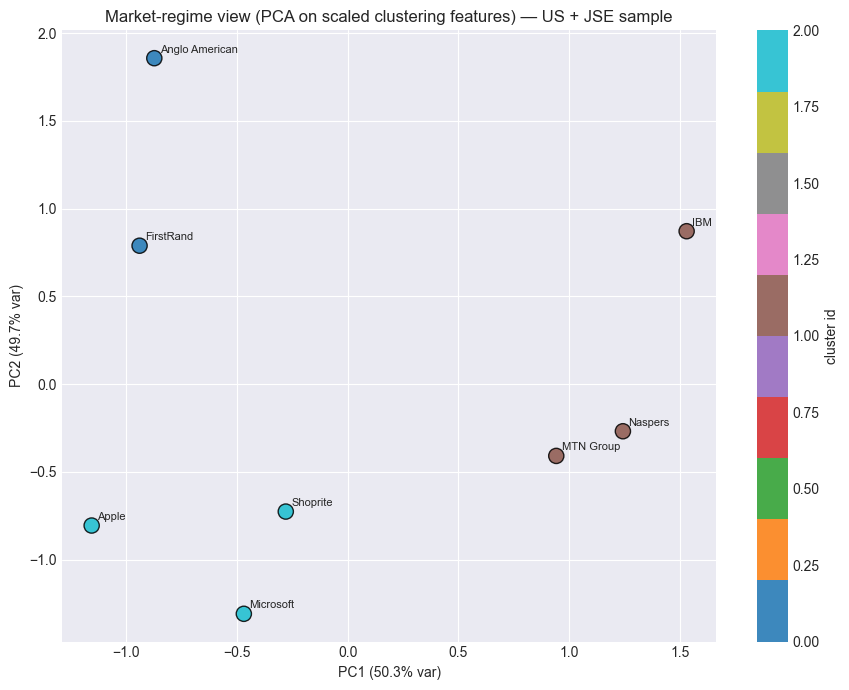

Explained variance ratio (PC1, PC2): [0.5029, 0.4971]
Saved: data/cluster_pca.png


In [ ]:
# Fit PCA on scaled data
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

fig, ax = plt.subplots(figsize=(9, 7))
scatter = ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cluster_series.values,
    cmap="tab10",
    s=120,
    edgecolor="k",
    alpha=0.85,
)
for i, name in enumerate(feature_df.index):
    ax.annotate(name, (X_pca[i, 0], X_pca[i, 1]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)")
ax.set_title("Market-regime view (PCA on scaled clustering features) — US + JSE sample")
plt.colorbar(scatter, ax=ax, label="cluster id")
plt.tight_layout()

os.makedirs("data", exist_ok=True)
plt.savefig("data/cluster_pca.png", dpi=150, bbox_inches="tight")
plt.show()

print(
    "Explained variance ratio (PC1, PC2):",
    pca.explained_variance_ratio_.round(4).tolist(),
)
print("Saved: data/cluster_pca.png")

### Results table — one row per ticker

We join raw window features with **cluster_id** and **cluster_label**.

This table is our **single source of truth** before JSON: e.g. **IBM** at **−0.1162%** mean and **3.5271** vol in **cluster 1**, versus **Apple** at **−0.2709%** mean but **1.3704** vol in **cluster 2**. Sorting by **volatility_daily_pct** ranks who was **choppiest** in the window; sorting by **mean_daily_return_pct** ranks drift **up vs down**; **cluster_id** shows **peers** for demos and copy.


In [10]:
results = feature_df.copy()
results["cluster_id"] = cluster_series
results["cluster_label"] = results["cluster_id"].map(label_map)
results.round(4)

,mean_daily_return_pct,volatility_daily_pct,cluster_id,cluster_label
Anglo American,-0.6358,2.8265,0,weaker_trend_high_volatility
Apple,-0.2709,1.3704,2,weaker_trend_moderate_volatility
FirstRand,-0.4822,2.2655,0,weaker_trend_high_volatility
IBM,-0.1162,3.5271,1,weaker_trend_high_volatility
Microsoft,-0.0885,1.4614,2,weaker_trend_moderate_volatility
MTN Group,-0.0101,2.6034,1,weaker_trend_high_volatility
Naspers,0.0144,2.8215,1,weaker_trend_high_volatility
Shoprite,-0.1487,1.8429,2,weaker_trend_moderate_volatility


### Export — `payload.json` and blurb

We call **`build_llm_payload`** with **`as_of`** (last aligned date), window length, universe note, per-stock metrics, cluster fields, and a **`classifier_note`** (no supervised forecaster). **`build_narrative_blurb`** turns that into one paragraph; we write **`data/payload.json`**.

In our run, **`as_of`** is **2026-03-18** and the blurb repeats the same numbers as the JSON—e.g. **Apple −0.2709% / 1.3704 vol / cluster 2**, **Naspers +0.0144% / 2.8215 / cluster 1**. We feed this file to **Streamlit** and **Notebook 03** so the assistant **quotes our measurements** instead of inventing vol or return figures.


In [ ]:
as_of = closes.index.max().date()
classifier_note = (
    "MVP: no supervised price forecaster; regime-style groups from k-means on recent "
    "return mean/vol features only. Not predictive and not investment advice."
)

payload = build_llm_payload(
    as_of=as_of,
    window=WINDOW,
    feature_df=feature_df,
    cluster_series=cluster_series.reindex(feature_df.index),
    cluster_label_map=label_map,
    classifier_note=classifier_note,
)
blurb = build_narrative_blurb(payload)

print(blurb)
print("\n--- payload.json (preview) ---\n")
print(json.dumps(payload, indent=2))

#
os.makedirs("data", exist_ok=True)
with open("data/payload.json", "w", encoding="utf-8") as f:
    json.dump(payload, f, indent=2)
print("\nWrote: data/payload.json (for Notebook 03 + Streamlit)")

As of 2026-03-18, Sample US + JSE names from cached OHLCV; educational only, not advice. Anglo American: last 20d avg daily return -0.6358%, volatility (std of daily returns) 2.8265%, cluster 0 (weaker_trend_high_volatility). Apple: last 20d avg daily return -0.2709%, volatility (std of daily returns) 1.3704%, cluster 2 (weaker_trend_moderate_volatility). FirstRand: last 20d avg daily return -0.4822%, volatility (std of daily returns) 2.2655%, cluster 0 (weaker_trend_high_volatility). IBM: last 20d avg daily return -0.1162%, volatility (std of daily returns) 3.5271%, cluster 1 (weaker_trend_high_volatility). Microsoft: last 20d avg daily return -0.0885%, volatility (std of daily returns) 1.4614%, cluster 2 (weaker_trend_moderate_volatility). MTN Group: last 20d avg daily return -0.0101%, volatility (std of daily returns) 2.6034%, cluster 1 (weaker_trend_high_volatility). Naspers: last 20d avg daily return 0.0144%, volatility (std of daily returns) 2.8215%, cluster 1 (weaker_trend_high_

### Risk posture preview

Each posture maps to **allowed** `cluster_label` strings; we list tickers from **`payload`** that qualify. Sets are **nested** (conservative ⊆ balanced ⊆ aggressive), so names can repeat across lists.

**Our printout:** **conservative** and **balanced** both return **`['Apple', 'Microsoft', 'Shoprite']`** — only **moderate-vol** labels matched anyone this run; **firmer_trend_*** labels had **no** stocks. **aggressive** lists **all eight**. This is a template for “show calmer regime tags first” in the UI—not buy/sell advice.

---

### What we take away

1. **Snapshot only:** Clusters and PCA describe the **last `WINDOW`** days (and long-window `describe` is separate history)—not long-run quality or future performance.  
2. **Peers, not winners:** K-means answers **who looked alike recently**, not **what to buy**.  
3. **Volatility is scale, not judgment:** High vol means **bigger daily swings**; we pair it with **mean return** for a full sentence.  
4. **Handoff:** **`data/payload.json`** plus **`data/cluster_pca.png`** are what we ship to **Notebook 03** and **Streamlit**.

Re-running after refreshing **`data/raw/`** refreshes every number and our story for the new window.


In [12]:
# Plan: map posture → allowed cluster_label strings; list tickers from payload (educational)
RISK_TO_LABELS = {
    "conservative": {
        "firmer_trend_moderate_volatility",
        "weaker_trend_moderate_volatility",
    },
    "balanced": {
        "firmer_trend_moderate_volatility",
        "weaker_trend_moderate_volatility",
        "firmer_trend_high_volatility",
    },
    "aggressive": {
        "firmer_trend_high_volatility",
        "weaker_trend_high_volatility",
        "firmer_trend_moderate_volatility",
        "weaker_trend_moderate_volatility",
    },
}

preview = {}
for posture, allowed in RISK_TO_LABELS.items():
    tickers = [
        name
        for name, info in payload["stocks"].items()
        if info["cluster_label"] in allowed
    ]
    preview[posture] = tickers

for posture, tickers in preview.items():
    print(f"{posture}: {tickers if tickers else '(none in allowed labels this run)'}")

conservative: ['Apple', 'Microsoft', 'Shoprite']
balanced: ['Apple', 'Microsoft', 'Shoprite']
aggressive: ['Anglo American', 'Apple', 'FirstRand', 'IBM', 'Microsoft', 'MTN Group', 'Naspers', 'Shoprite']


---

## Notebook 02 — our summary

We aligned **98** dates for **eight** names, built **97** rows of daily returns, summarized **20** days into mean + vol, ran **k=3** k-means and PCA (**~50.3% / 49.7%** variance on PC1/PC2 in our run), and exported **`data/payload.json`** (**as_of 2026-03-18**) with a matching narrative blurb and **`data/cluster_pca.png`**.

**Caveats:** Small universe, mixed currencies in **levels**, short sample, heuristic labels — we use this for **learning and grounded narrative**, not trading decisions.
